# Milestone 3 - Exploratory Data Analysis (EDA)

**Project:** Airline Flight Delay Prediction & Explainable AI
**Data:** `flights_2008_clean.csv` (the clean file we saved at the end of Milestone 2)

In this notebook we look for the patterns behind flight delays. Every chart is followed by a **Takeaway**, which is what the chart tells us and why it matters for an airline.

Sections:
1. Load the data and choose the flights to study
2. The target: how many flights arrive late?
3. Departure delay vs arrival delay
4. When do delays happen? (hour, month, day of week)
5. Why do delays happen? (delay causes)
6. Who and where? (airlines and airports)
7. Distance
8. Correlation analysis (and what it does NOT prove)
9. Summary of business insights

## 1. Load the data

**Why:** we start from the Milestone 2 clean file, so all the cleaning decisions (duplicates, data types, impossible rows, missing values) are already applied and we don't repeat them here.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 4)

df = pd.read_csv('flights_2008_clean.csv')
print('rows, columns:', df.shape)
df.head()

rows, columns: (1936743, 33)


,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,FlightDate,SuspectAirTime,CRSElapsedTimeFilled,ExtremeDelay
0,2008,1,3,4,2003,1955,2211.0,2225,WN,335,...,0,0.0,0.0,0.0,0.0,0.0,2008-01-03,0,0,0
1,2008,1,3,4,754,735,1002.0,1000,WN,3231,...,0,0.0,0.0,0.0,0.0,0.0,2008-01-03,0,0,0
2,2008,1,3,4,628,620,804.0,750,WN,448,...,0,0.0,0.0,0.0,0.0,0.0,2008-01-03,0,0,0
3,2008,1,3,4,1829,1755,1959.0,1925,WN,3920,...,0,2.0,0.0,0.0,0.0,32.0,2008-01-03,0,0,0
4,2008,1,3,4,1940,1915,2121.0,2110,WN,378,...,0,0.0,0.0,0.0,0.0,0.0,2008-01-03,0,0,0


**Which flights do we study?**
We keep only flights that were **not cancelled and not diverted**.

**Why:** cancelled and diverted flights never arrived where they were scheduled, so they have no arrival delay (we kept these values empty on purpose in Milestone 2). Our question is about arrival delay, so these flights can't answer it.

**Our definition of "delayed":** the flight arrived **15 minutes or more** after its scheduled time.
**Why 15 minutes:** this is the official US Department of Transportation definition of a delayed flight, and it is also the point where the delay-cause columns start being recorded in this dataset.

We also add `DepHour` (the scheduled departure hour) here, because `CRSDepTime` is stored as hhmm (e.g. 1755 = 17:55) and is hard to read on a chart.

In [2]:
flights = df[(df['Cancelled'] == 0) & (df['Diverted'] == 0)].copy()

flights['IsDelayed'] = (flights['ArrDelay'] >= 15).astype(int)
flights['DepHour'] = (flights['CRSDepTime'] // 100) % 24

print('flights we study:', len(flights))
print('removed (cancelled or diverted):', len(df) - len(flights))

flights we study: 1928361
removed (cancelled or diverted): 8382


## 2. The target: how many flights arrive late?

**Why:** before anything else we need to know how balanced the target is. It tells us which metrics will make sense later (if 90% of flights were delayed, a model that always says "delayed" would look very good on accuracy).

delayed 15+ min:

 64.7 %


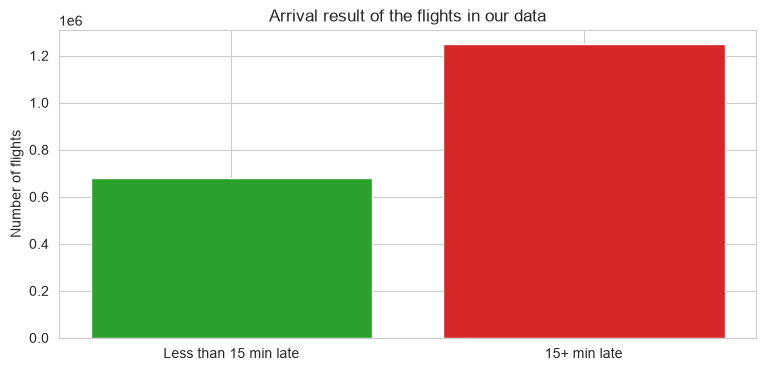

In [3]:
counts = flights['IsDelayed'].value_counts().sort_index()
share = flights['IsDelayed'].mean() * 100
print('delayed 15+ min:', round(share, 1), '%')

plt.bar(['Less than 15 min late', '15+ min late'], counts.values, color=['tab:green', 'tab:red'])
plt.title('Arrival result of the flights in our data')
plt.ylabel('Number of flights')
plt.show()

**Takeaway:** about **65%** of the flights in this file arrived 15+ minutes late. This is NOT the national delay rate: the dataset only contains flights that **left the gate 6+ minutes late** (see Milestone 2). So the real question our data can answer is: *"once a flight leaves late, will it still arrive late?"*

The classes are not perfectly balanced (65 / 35), so later we will look at precision, recall and F1, not only accuracy.

### Arrival delay distribution

**Why:** we want to see the shape of the delay values (normal? skewed?) because it affects scaling and model choice in the next milestones.

mean arrival delay  : 42.2 min
median arrival delay: 24.0 min
max arrival delay   : 2461.0 min


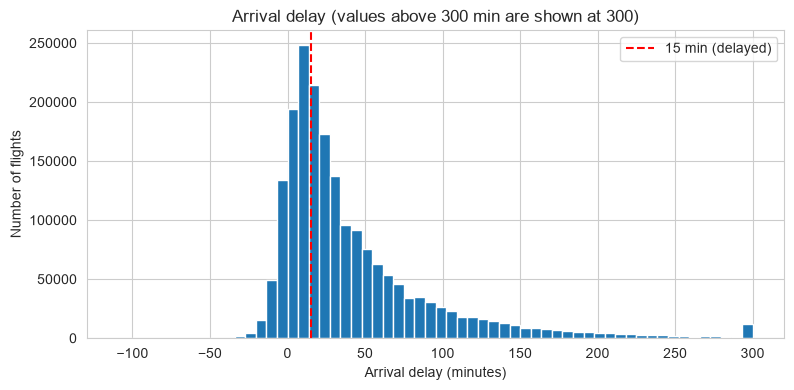

In [4]:
print('mean arrival delay  :', round(flights['ArrDelay'].mean(), 1), 'min')
print('median arrival delay:', flights['ArrDelay'].median(), 'min')
print('max arrival delay   :', flights['ArrDelay'].max(), 'min')

# cut the x axis at 300 minutes so the main part of the chart is readable
plt.hist(flights['ArrDelay'].clip(upper=300), bins=60, color='tab:blue')
plt.axvline(15, color='red', linestyle='--', label='15 min (delayed)')
plt.title('Arrival delay (values above 300 min are shown at 300)')
plt.xlabel('Arrival delay (minutes)')
plt.ylabel('Number of flights')
plt.legend()
plt.show()

**Takeaway:** the distribution is strongly **right-skewed**: the median is 24 minutes, but the mean is 42 minutes because a few flights are many hours late (the longest is about 41 hours). Because of this skew we will use a log transform for the delay feature in preprocessing, and we report medians when we talk about "typical" delays.

## 3. Departure delay vs arrival delay

**Why:** our flights already left late. The first thing a dispatcher knows at the gate is *how* late. We want to see how much of the arrival result is already decided at that moment.

DepDelayBand
6-14       22.1
15-29      60.6
30-59      96.1
60-119    100.0
120+      100.0
Name: IsDelayed, dtype: float64


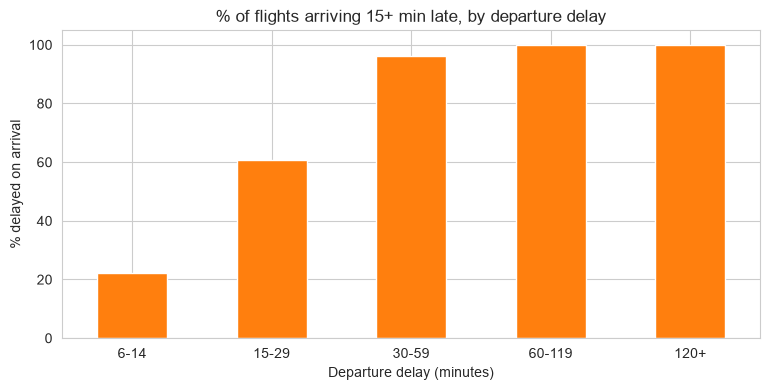

In [5]:
bands = [5, 14, 29, 59, 119, 10000]
labels = ['6-14', '15-29', '30-59', '60-119', '120+']
flights['DepDelayBand'] = pd.cut(flights['DepDelay'], bins=bands, labels=labels)

band_rate = flights.groupby('DepDelayBand', observed=True)['IsDelayed'].mean() * 100
print(band_rate.round(1))

band_rate.plot(kind='bar', color='tab:orange')
plt.title('% of flights arriving 15+ min late, by departure delay')
plt.xlabel('Departure delay (minutes)')
plt.ylabel('% delayed on arrival')
plt.xticks(rotation=0)
plt.show()

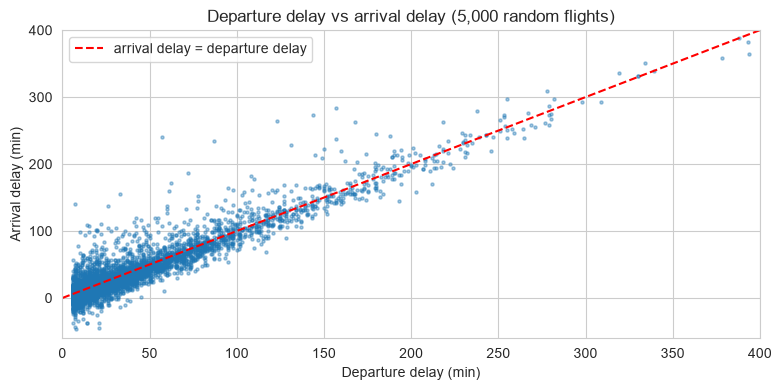

In [6]:
# scatter plot on a random sample, 1.9 million points would just be one big blob
sample = flights.sample(5000, random_state=42)
plt.scatter(sample['DepDelay'], sample['ArrDelay'], s=5, alpha=0.4)
plt.plot([0, 400], [0, 400], color='red', linestyle='--', label='arrival delay = departure delay')
plt.xlim(0, 400)
plt.ylim(-60, 400)
plt.title('Departure delay vs arrival delay (5,000 random flights)')
plt.xlabel('Departure delay (min)')
plt.ylabel('Arrival delay (min)')
plt.legend()
plt.show()

**Takeaway:** flights that leave **30+ minutes late arrive late 96-100% of the time**, while flights that leave only **6-14 minutes late arrive late just 22% of the time**. Most points sit close to the red line, so a plane rarely "makes up" much time in the air.

**Business meaning:** the first 15-30 minutes of a delay at the gate is where the airline can still save the arrival. After about 30 minutes the late arrival is almost certain, so the focus should move to protecting the *next* flights of that aircraft and passenger connections.

## 4. When do delays happen?

### By scheduled departure hour

**Why:** the "domino effect" from our proposal says delays build up during the day. If that is true, the share of delayed flights should rise from morning to evening.

         % delayed  flights
DepHour                    
5             59.3     4509
6             58.5    50267
7             60.5    61550
8             61.2    82243
9             60.8    95295
10            60.5   108994
11            61.1   122384
12            61.9   123713
13            63.4   141777
14            64.0   141127
15            64.5   142106
16            66.4   156038
17            67.5   163699
18            69.1   153774
19            69.1   145732
20            68.9   106328
21            69.0    89680
22            63.9    25675
23            59.8    10250


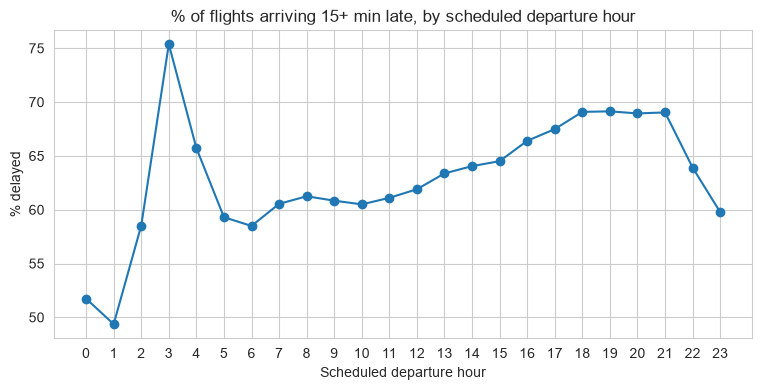

In [7]:
hour_rate = flights.groupby('DepHour')['IsDelayed'].mean() * 100
hour_count = flights.groupby('DepHour').size()
print(pd.DataFrame({'% delayed': hour_rate.round(1), 'flights': hour_count}).loc[5:23])

plt.plot(hour_rate.index, hour_rate.values, marker='o')
plt.title('% of flights arriving 15+ min late, by scheduled departure hour')
plt.xlabel('Scheduled departure hour')
plt.ylabel('% delayed')
plt.xticks(range(0, 24))
plt.show()

**Takeaway:** the delayed share rises steadily from about **58-59% for 5-6 am departures to about 69% for 6-9 pm departures**. Hours 0-4 jump around because there are very few flights (under 3,000 per hour), so we don't read much into them.

**Business meaning:** early flights are the most reliable. Evening flights carry the delays collected during the day, which supports the domino-effect idea (we check this directly in section 5).

### By month

**Why:** weather and holiday traffic change across the year, so we expect a seasonal pattern.

       % delayed  flights
Month                    
1           66.0   182913
2           68.3   188622
3           65.5   200113
4           63.1   154783
5           62.1   152709
6           68.3   199888
7           65.5   182171
8           62.1   161974
9           58.5    95351
10          55.3   103181
11          60.7   105148
12          70.2   201508


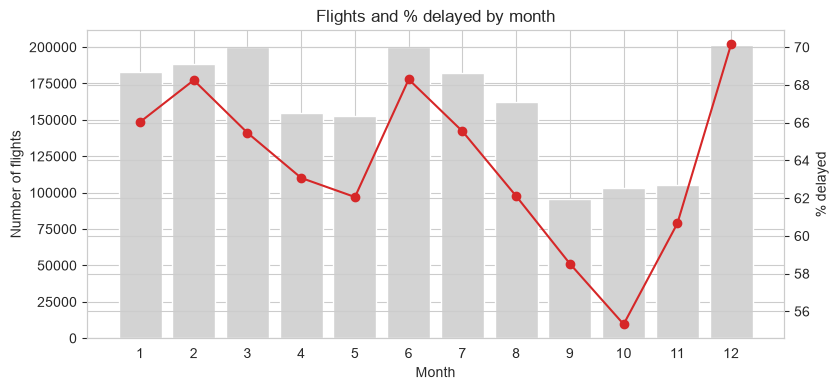

In [8]:
month_rate = flights.groupby('Month')['IsDelayed'].mean() * 100
month_count = flights.groupby('Month').size()
print(pd.DataFrame({'% delayed': month_rate.round(1), 'flights': month_count}))

fig, ax1 = plt.subplots()
ax1.bar(month_count.index, month_count.values, color='lightgray', label='number of flights')
ax1.set_ylabel('Number of flights')
ax1.set_xlabel('Month')
ax2 = ax1.twinx()
ax2.plot(month_rate.index, month_rate.values, color='tab:red', marker='o', label='% delayed')
ax2.set_ylabel('% delayed')
plt.title('Flights and % delayed by month')
plt.xticks(range(1, 13))
plt.show()

**Takeaway:** **December is the worst month (about 70% delayed)**, and **October is the best (about 55%)**. December also has the most late-departing flights in the file, while September-November have only about half as many. Winter (Dec-Feb) and the start of summer (June) are the high-risk periods.

**Business meaning:** extra crew and spare aircraft are most valuable in December and June. Because the pattern goes up and down (it is not a straight line from January to December), we will turn months into **seasons** during feature engineering instead of using the month number directly.

### By day of week

**Why:** we want to know if weekdays and weekends behave differently, to decide if day of week is worth keeping as a feature.

DayOfWeek
Mon    64.5
Tue    65.5
Wed    64.1
Thu    64.8
Fri    66.5
Sat    61.5
Sun    65.0
Name: IsDelayed, dtype: float64


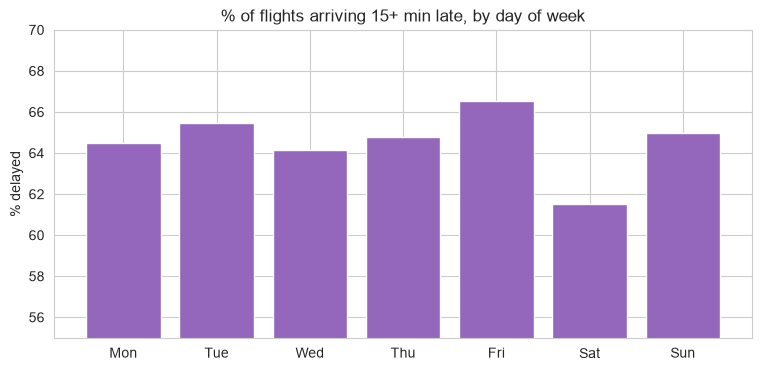

In [9]:
day_names = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat', 7: 'Sun'}
day_rate = flights.groupby('DayOfWeek')['IsDelayed'].mean() * 100
print(day_rate.round(1).rename(day_names))

plt.bar(day_rate.index.map(day_names), day_rate.values, color='tab:purple')
plt.ylim(55, 70)
plt.title('% of flights arriving 15+ min late, by day of week')
plt.ylabel('% delayed')
plt.show()

**Takeaway:** the differences are small: **Friday is the worst (about 66.5%) and Saturday the best (about 61.5%)**. (Note the y axis starts at 55% so the differences are visible.) Day of week matters much less than departure delay or hour, but we keep it as a feature and let the model decide how useful it is.

## 5. Why do delays happen?

**Why:** our project is about explaining delays, not only predicting them. The five cause columns split each delayed flight's minutes into carrier, weather, NAS (air traffic system), security and late-arriving aircraft.

CarrierDelay         30.3
WeatherDelay          5.9
NASDelay             23.7
SecurityDelay         0.1
LateAircraftDelay    40.0
dtype: float64


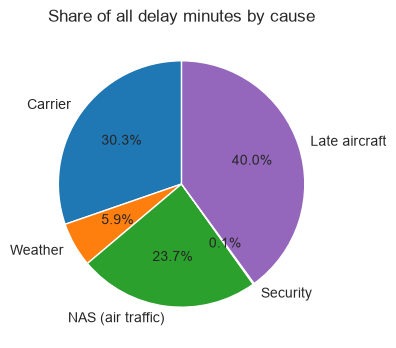

In [10]:
causes = ['CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
total_minutes = flights[causes].sum()
print((total_minutes / total_minutes.sum() * 100).round(1))

plt.pie(total_minutes, labels=['Carrier', 'Weather', 'NAS (air traffic)', 'Security', 'Late aircraft'],
        autopct='%1.1f%%', startangle=90)
plt.title('Share of all delay minutes by cause')
plt.show()

**Takeaway:** **late-arriving aircraft cause 40% of all delay minutes**, more than any other cause. Carrier problems (crew, maintenance, cleaning, baggage) cause 30% and the air traffic system 24%. Weather as its own cause is only about 6% (part of the weather effect is also counted inside NAS delays). This matches the ~40% "domino effect" number in our proposal.

         CarrierDelay  WeatherDelay  NASDelay  SecurityDelay  \
DepHour                                                        
6                67.2          10.1      17.9            0.5   
12               29.3           4.9      27.3            0.1   
19               24.3           6.1      18.9            0.1   

         LateAircraftDelay  
DepHour                     
6                      4.3  
12                    38.4  
19                    50.6  


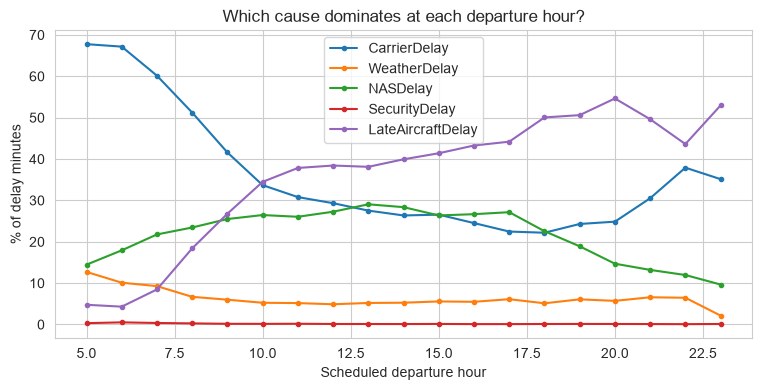

In [11]:
hour_causes = flights.groupby('DepHour')[causes].sum()
hour_causes_pct = hour_causes.div(hour_causes.sum(axis=1), axis=0) * 100
hour_causes_pct = hour_causes_pct.loc[5:23]   # hours 0-4 have too few flights
print(hour_causes_pct.loc[[6, 12, 19]].round(1))

for c in causes:
    plt.plot(hour_causes_pct.index, hour_causes_pct[c], marker='.', label=c)
plt.title('Which cause dominates at each departure hour?')
plt.xlabel('Scheduled departure hour')
plt.ylabel('% of delay minutes')
plt.legend()
plt.show()

**Takeaway:** this chart shows the domino effect directly. At **6 am, late aircraft cause only about 4% of delay minutes and carrier problems about 67%** (the first flight of the day has no earlier flight to wait for). By **7 pm, late aircraft cause about 51%** of the delay minutes.

**Business meaning:** morning delays are mostly the airline's own operations, so better turnaround and maintenance planning helps there. Evening delays are mostly inherited from earlier flights, so bigger schedule buffers between flights in the afternoon would stop delays from spreading.

## 6. Who and where? Airlines and airports

**Why:** if some airlines or airports are clearly worse, they are useful features, and they are also an insight the business can act on.

               pct_delayed  flights
UniqueCarrier                      
AQ                    45.7      744
WN                    54.1   376201
F9                    56.5    28222
HA                    57.9     7472
CO                    59.1    99731
US                    60.7    98007
AS                    61.6    39010
DL                    63.5   113728
FL                    66.2    70969
OO                    67.5   131773
UA                    67.8   140904
MQ                    69.1   141223
9E                    69.1    51569
AA                    69.3   190910
NW                    69.4    78843
EV                    69.4    81762
B6                    69.6    54925
XE                    69.8   103146
OH                    74.9    52453
YV                    75.9    66769


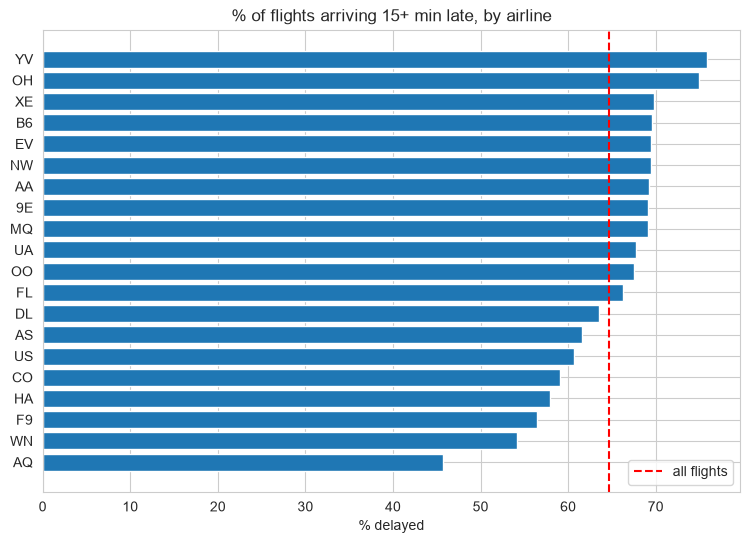

In [12]:
carrier = flights.groupby('UniqueCarrier', observed=True).agg(pct_delayed=('IsDelayed', 'mean'), flights=('IsDelayed', 'size'))
carrier['pct_delayed'] = carrier['pct_delayed'] * 100
carrier = carrier.sort_values('pct_delayed')
print(carrier.round(1))

plt.figure(figsize=(9, 6))
plt.barh(carrier.index.astype(str), carrier['pct_delayed'], color='tab:blue')
plt.axvline(flights['IsDelayed'].mean() * 100, color='red', linestyle='--', label='all flights')
plt.title('% of flights arriving 15+ min late, by airline')
plt.xlabel('% delayed')
plt.legend()
plt.show()

**Takeaway:** **YV (Mesa) and OH (Comair) are the worst, with about 75-76% of their late departures arriving late**. **WN (Southwest), the biggest airline in the file with about 376,000 flights, is the best of the large airlines at about 54%**. AQ looks best (about 46%) but it has only 744 flights, so we don't trust that number much.

**Business meaning:** once its flights leave late, Southwest recovers much more often than the regional airlines do. That makes the airline a strong feature for the model.

        pct_delayed  flights
Origin                      
PHX            55.9    55506
LAS            56.1    53535
LAX            57.6    58544
IAH            58.6    56571
MCO            62.0    35959
DEN            62.8    74032
DFW            65.3    95058
ATL            66.9   131213
EWR            68.5    52756
SFO            69.0    43635
DTW            70.3    43721
ORD            72.2   125451


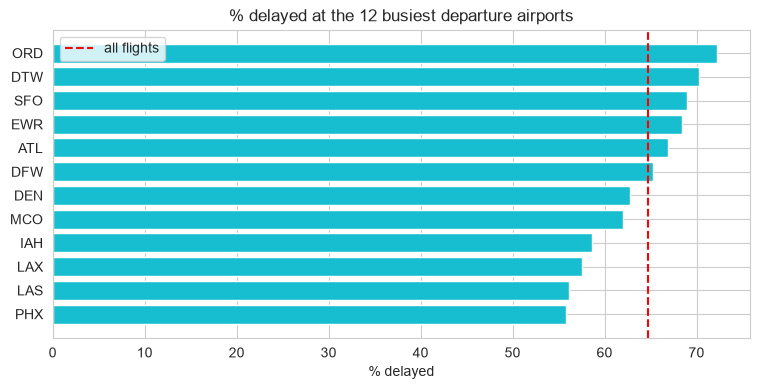

In [13]:
airport = flights.groupby('Origin', observed=True).agg(pct_delayed=('IsDelayed', 'mean'), flights=('IsDelayed', 'size'))
airport['pct_delayed'] = airport['pct_delayed'] * 100
top_airports = airport.sort_values('flights', ascending=False).head(12).sort_values('pct_delayed')
print(top_airports.round(1))

plt.barh(top_airports.index.astype(str), top_airports['pct_delayed'], color='tab:cyan')
plt.axvline(flights['IsDelayed'].mean() * 100, color='red', linestyle='--', label='all flights')
plt.title('% delayed at the 12 busiest departure airports')
plt.xlabel('% delayed')
plt.legend()
plt.show()

**Takeaway:** among the 12 busiest airports, **Chicago O'Hare (ORD) is the worst at about 72%**, followed by Detroit (DTW) and San Francisco (SFO) at about 69-70%. **Phoenix (PHX) and Las Vegas (LAS) are the best at about 56%**. Busy hubs with cold winters or frequent fog are worse; warm, dry airports are better.

There are 303 airports, and many have very few flights, so in preprocessing we keep the busiest ones and group the rest as "Other".

## 7. Distance

**Why:** a longer flight has more time in the air, so the pilots might "make up" some of the delay. We check if that shows in the data.

DistanceBand
0-300        68.4
300-600      65.7
600-1000     64.3
1000-1500    62.3
1500+        59.3
Name: IsDelayed, dtype: float64


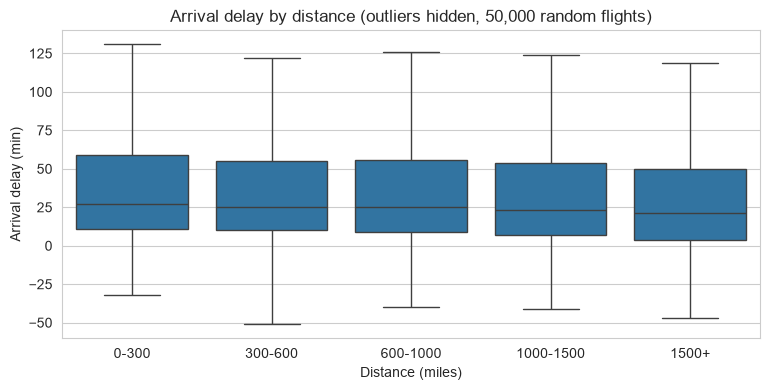

In [14]:
dist_bins = [0, 300, 600, 1000, 1500, 5000]
dist_labels = ['0-300', '300-600', '600-1000', '1000-1500', '1500+']
flights['DistanceBand'] = pd.cut(flights['Distance'], bins=dist_bins, labels=dist_labels)
dist_rate = flights.groupby('DistanceBand', observed=True)['IsDelayed'].mean() * 100
print(dist_rate.round(1))

sns.boxplot(data=flights.sample(50000, random_state=1), x='DistanceBand', y='ArrDelay', showfliers=False)
plt.title('Arrival delay by distance (outliers hidden, 50,000 random flights)')
plt.xlabel('Distance (miles)')
plt.ylabel('Arrival delay (min)')
plt.show()

**Takeaway:** **short flights (300 miles or less) arrive late about 68% of the time, while long flights (over 1,500 miles) arrive late about 59% of the time**. Distance has some effect, but it is much weaker than departure delay. Section 8 shows this is not necessarily because distance itself "causes" anything.

## 8. Correlation analysis

**Why:** a correlation heatmap shows quickly which numeric columns move together. We use it for two things: (1) to find columns that are almost copies of each other (redundant), and (2) to find columns that are suspiciously strong because they are part of the answer (leakage).

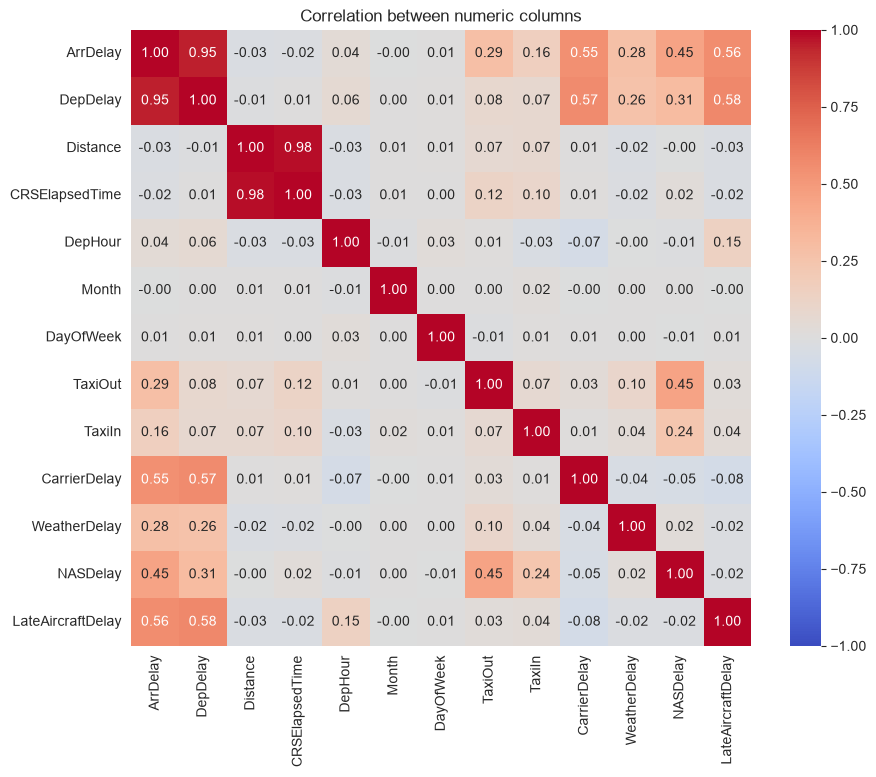

correlation with ArrDelay:
DepDelay             0.95
LateAircraftDelay    0.56
CarrierDelay         0.55
NASDelay             0.45
TaxiOut              0.29
WeatherDelay         0.28
TaxiIn               0.16
DepHour              0.04
DayOfWeek            0.01
Month               -0.00
CRSElapsedTime      -0.02
Distance            -0.03
Name: ArrDelay, dtype: float64


In [15]:
corr_cols = ['ArrDelay', 'DepDelay', 'Distance', 'CRSElapsedTime', 'DepHour', 'Month', 'DayOfWeek',
             'TaxiOut', 'TaxiIn', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'LateAircraftDelay']
corr = flights[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation between numeric columns')
plt.show()

print('correlation with ArrDelay:')
print(corr['ArrDelay'].drop('ArrDelay').sort_values(ascending=False).round(2))

**What the correlations show:**
- **DepDelay vs ArrDelay = 0.95.** Very strong. This is the same thing we saw in section 3.
- **The delay causes (0.28-0.56) are high for a bad reason.** Together they add up exactly to `ArrDelay` (we proved this in Milestone 2), so they are *parts of the answer*, not predictors. They are only known after the flight lands, so we must not use them as model inputs (leakage).
- **TaxiOut / TaxiIn (0.29 / 0.16)** are also only known after departure or after landing, so they are left out as well.
- **Distance vs CRSElapsedTime = 0.98.** These two columns carry almost the same information (a longer flight is scheduled for longer), so we keep only one of them (`Distance`) to avoid redundancy.
- **Hour, month, day of week, distance all have weak correlation (under 0.05 in absolute value).** That does **not** mean they are useless. Correlation only measures *straight-line* relationships. The hour chart goes up and the month chart goes up and down, and a straight line can't describe those shapes well. Tree models in Milestone 4 can learn them.

**What the correlations do NOT prove (correlation is not causation):**
- High correlation between `DepDelay` and `ArrDelay` does not mean departure delay is the *root cause*. Both are results of something else (weather, a late inbound plane, a crew problem). This is exactly why we need the explainability part of the project.
- "Short flights are delayed more" looks like distance causes delay, but there is a hidden third factor: **regional airlines fly 55% of the short flights (300 miles or less) but only 7% of the long ones (over 1,000 miles)**, and regional airlines are delayed more often (about 70% vs 62% for the big airlines). So the airline, not the distance, may be behind much of that pattern. We can't separate the two with correlation alone.

In [16]:
regional = ['9E', 'MQ', 'OO', 'XE', 'YV', 'OH', 'EV']
flights['Regional'] = flights['UniqueCarrier'].isin(regional)

print('share of short flights (<= 300 mi) flown by regional airlines:', round(flights.loc[flights['Distance'] <= 300, 'Regional'].mean() * 100, 1), '%')
print('share of long flights (> 1000 mi) flown by regional airlines :', round(flights.loc[flights['Distance'] > 1000, 'Regional'].mean() * 100, 1), '%')
print('% delayed, regional airlines:', round(flights.loc[flights['Regional'], 'IsDelayed'].mean() * 100, 1))
print('% delayed, other airlines   :', round(flights.loc[~flights['Regional'], 'IsDelayed'].mean() * 100, 1))

share of short flights (<= 300 mi) flown by regional airlines: 55.2 %
share of long flights (> 1000 mi) flown by regional airlines : 7.0 %
% delayed, regional airlines: 70.1
% delayed, other airlines   : 62.1


## 9. Summary of business insights

1. **The first 30 minutes decide the arrival.** Flights leaving 6-14 min late arrive late 22% of the time; flights leaving 30+ min late arrive late 96-100% of the time. Airlines should act during the first half hour of a gate delay.
2. **Delays snowball during the day.** Late-arriving aircraft cause about 4% of delay minutes at 6 am but about 51% at 7 pm, and the delayed share rises from about 58% to 69%. Bigger buffers between afternoon flights would stop the chain.
3. **Late aircraft are the biggest single cause** (40% of all delay minutes), ahead of carrier problems (30%) and air traffic (24%).
4. **December is the riskiest month (about 70% delayed), October the safest (about 55%).** Extra spare capacity is most useful in winter and June.
5. **The airline matters.** Southwest recovers from late departures far more often (54% arrive late) than Mesa or Comair (75-76%).
6. **Hub airports with harsh weather are worse.** ORD (72%) vs PHX and LAS (56%).
7. **Be careful with correlations.** Delay-cause and taxi columns are part of the answer and must not be used as inputs. Distance looks important but is mixed up with the type of airline.

**What this means for preprocessing (next notebook):**
- Use departure delay as an input (it is known at the moment the plane leaves), with a log transform because of the skew.
- Drop the delay-cause, taxi and other after-departure columns (leakage).
- Turn hhmm times into hours and months into seasons.
- Keep `Distance`, drop `CRSElapsedTime` (0.98 correlation).
- Group the many small airports into "Other".